# All-Weather Portfolio ##

## Table of Contents
[1. Prices](#prices)

[2. Portfolio Construction](#construction)

[3. Backtest against Benchmark](#backtest)

[4. Diversifying All-Weather Portfolio: Global Minimum Variance](#modern)

[5. Diversifying All-Weather Portfolio: Bonds and Metals](#bonds)

[6. Portfolio Construction with New Sleeves](#sleeves)

[7. Constraints to Equal Risk Portfolio](#constraint)

[8. Conclusions and Limitations](#conclusion)

In [69]:
#importing important libraries for data analysis, pulling financial date and mathematical functions
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
from scipy.optimize import minimize

# importing portfolio management module
import edhec_risk_kit_206 as erk

#ensures any edits to modules are available to be used
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


<a id='prices'></a>
## 1. Prices

In [70]:
# tickers for broard etfs of what makes up the all world portfolio
tickers = ['VTI', 'TLT', 'GLD', 'IEF', 'DBC']
start_date = '2006-09-06'
end_date = '2026-09-06'
# The typical all weather portfolio is built up of equities, long dated bonds, short term dated bonds, gold and a basket of commodities.
prices = yf.download(tickers, start_date, end_date)['Close']

[*********************100%***********************]  5 of 5 completed


<Axes: xlabel='Date'>

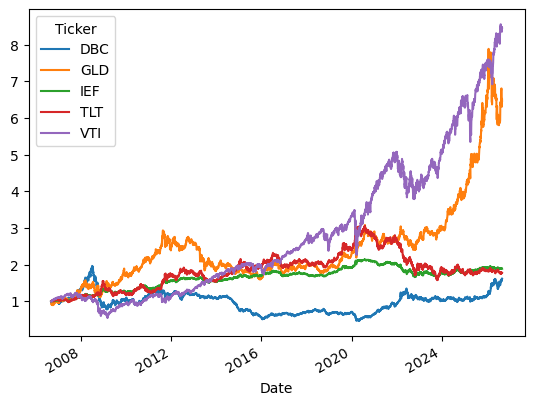

In [71]:
# returns and wealth index of each etf
rets = prices.pct_change().dropna()
rets_cumprod = (1 + rets ).cumprod()
rets_cumprod.plot()

,Annualized Return,Annualized Vol,Skewness,Kurtosis,Cornish-Fisher VaR (5%),Historic CVaR (5%),Sharpe Ratio,Max Drawdown
DBC,0.02443,0.18897,-0.55690,4.91603,0.09221,0.12398,-0.02892,-0.74553
GLD,0.09744,0.17359,-0.03253,3.22558,0.07347,0.09584,0.37791,-0.42910
IEF,0.03219,0.06586,0.18841,3.75984,0.02707,0.03758,0.03226,-0.23153
TLT,0.02901,0.13879,0.44316,4.28090,0.05637,0.07510,-0.00709,-0.47614
VTI,0.11217,0.15730,-0.57959,4.20423,0.07068,0.09766,0.50822,-0.50843


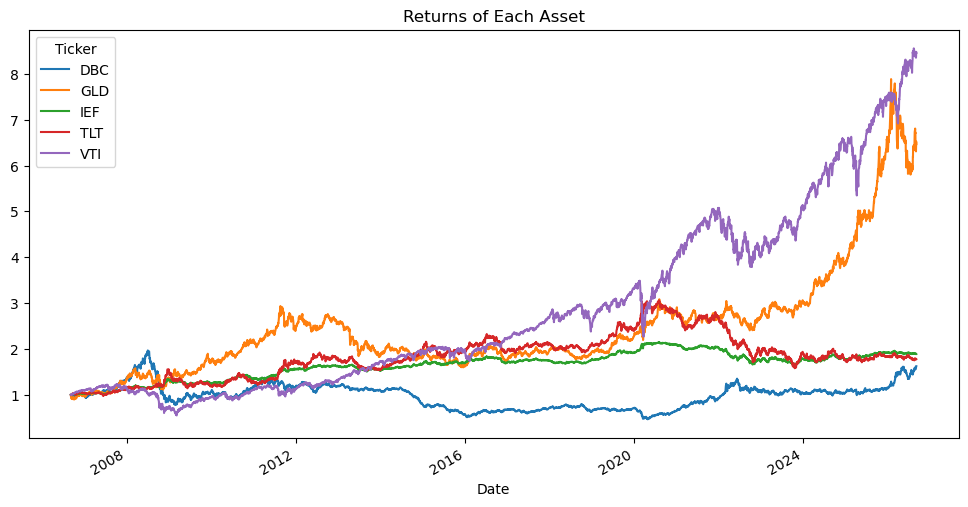

In [72]:
# contextualising what the returns and vol of each asset is so when looking at each weighting later on we should see a higher weighting for low vol assets and lower weighting for high vol assets.
rets_monthly = ( 1 + rets).resample('ME').prod() - 1
wealth = (1 + rets).cumprod()
wealth.plot(figsize=(12,6), title='Returns of Each Asset')

rets_stats = pd.DataFrame({
    ticker: rets_monthly[ticker] for ticker in rets_monthly.columns
})
display(erk.summary_stats(rets_stats.dropna()).round(5))

In [73]:
# isolating the returns of each asset
rets_eq = rets['VTI']
rets_bonds = rets['TLT']
rets_bonds_m = (1 + rets_bonds).resample('ME').prod() - 1
rets_ief = rets['IEF']
rets_gold = rets['GLD']
rets_gold_m = (1 + rets_gold).resample('ME').prod() - 1
rets_com = rets['DBC']

<a id='construction'></a>
## 2. Portfolio Construction

In [74]:
# The portfolio is meant to be a risk parity portfolio, lets see how close it is to the normal expected weightings from Bridgewater's report.

VTI    0.173087
TLT    0.124555
GLD    0.350603
IEF    0.172817
DBC    0.178938
dtype: float64

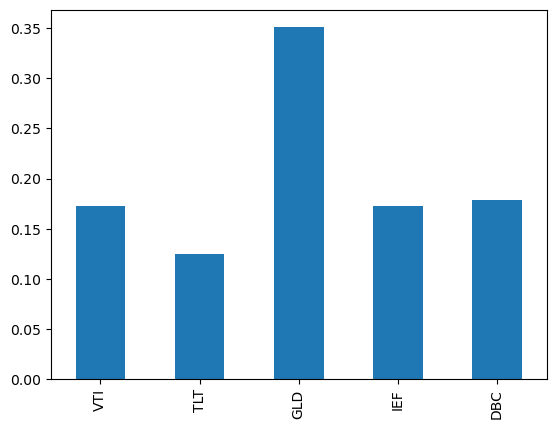

In [75]:
cov = erk.shrinkage_cov(rets['2023':])
er_weights = erk.equal_risk_contributions(cov)
weight_series = pd.Series(np.array(er_weights), index=tickers)
weight_series.plot.bar(stacked=True)
display(weight_series)

<a id='backtest'></a>
## 3. Backtest against Benchmarks

In [76]:
# Making my daily returns monthly
monthly_rets = prices.resample('ME').last().pct_change().dropna()

# Backtesting the equal risk portfolio
bt = erk.backtest_ws(monthly_rets,
                     36, 
                     weighting = lambda r: pd.Series(np.array(er_weights), index=r.columns))

# Benchmark the performance to an equal weighted portfolio
ewbt = erk.backtest_ws(monthly_rets,
                       36,
                       weighting = erk.weight_ew)

# Traditional weighting scheme associated with the portfolio
trad_weights = pd.Series({'VTI' : 0.3, 'TLT' : 0.4, 'IEF' : 0.15, 'GLD' : 0.075, 'DBC' : 0.075})

def weight_fixed(r, **kwargs):
    return trad_weights
tbt = erk.backtest_ws(monthly_rets, 36, weighting=weight_fixed)

# Stats of the following portfolios
btr = pd.DataFrame({'All Weather ER Portfolio' : bt,
                    'Equal weighted Portfolio' : ewbt,
                    'Traditional All-Weather Portfolio' : tbt})
erk.summary_stats(btr.dropna())

,Annualized Return,Annualized Vol,Skewness,Kurtosis,Cornish-Fisher VaR (5%),Historic CVaR (5%),Sharpe Ratio,Max Drawdown
All Weather ER Portfolio,0.058924,0.067491,-0.256732,3.076585,0.028361,0.036856,0.417032,-0.142810
Equal weighted Portfolio,0.067297,0.077021,-0.159378,2.787929,0.031884,0.041097,0.471217,-0.147768
Traditional All-Weather Portfolio,0.067843,0.079081,-0.327347,3.837842,0.033401,0.044731,0.465663,-0.222288


<Axes: xlabel='Date'>

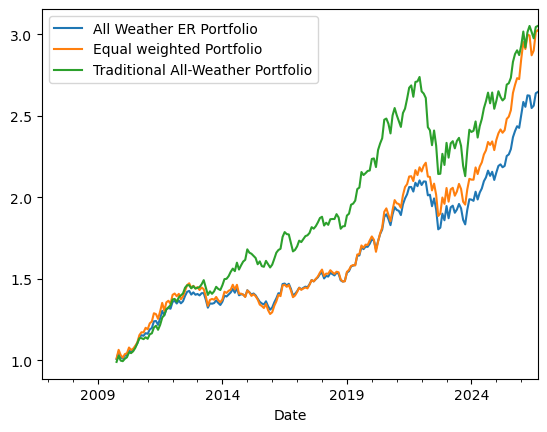

In [77]:
(btr + 1).cumprod().plot()

<a id='modern'></a>
## 4. Diversifying All-Weather Portfolio: GMV

##### Currently the weightings are slightly skewed away from equities and towards gold due to it's low volatility over this long period. I think we should reassess the weightings towards a more recent covariance matrix that reflects more contemporary volatility and allocate equity and gold weightings to low volatility equity baskets and metal baskets. This should allow the equity and metal baskets to have a higher weighting without sacrificing it's defensive drawdown and low volatility properties.

### GMV sleeve in place of VTI

In [78]:
# Trying to create a less volatile equity basket and introducing a new benchmark that is more US focused.
sector_etfs = ['XLK', 'XLF', 'XLV', 'XLE', 'XLY', 'XLP', 'XLI', 'XLB', 'XLU', 'XLRE']

# prices of benchmarks
smp_500 = yf.download('VOO', start='2006-09-06')['Close'].squeeze()
prices_sector = yf.download(sector_etfs, start='2006-09-06')['Close']
vti = yf.download('VTI', start='2006-09-06')['Close'].squeeze()

# prices to returns then from daily to monthly returns
sector_rets = prices_sector.pct_change().dropna()
sector_rets_m = (1 + sector_rets).resample('ME').prod() -1
smp_500_rets = smp_500.pct_change().dropna()
smp_500_rets_m = (1 + smp_500_rets).resample('ME').prod() -1
vti_rets = vti.pct_change().dropna()
vti_rets_m = (1 + rets_eq).resample('ME').prod() - 1

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  10 of 10 completed
[*********************100%***********************]  1 of 1 completed


In [79]:
# shrinking covariance matrix and creating returns of the gmv portfolio
rets_shrunk = erk.shrinkage_cov(sector_rets_m)
sector_gmv = erk.gmv(rets_shrunk)
sector_gmv_rets = sector_rets_m @ sector_gmv
gmv_rets_d = sector_rets @ sector_gmv

/home/df73671d-916e-4a3a-9bba-0038631a0a29/edhec_risk_kit_206.py:586: FutureWarning: The provided callable <function max at 0x7991782d8c20> is currently using DataFrame.max. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "max" instead.
  best_month = r.aggregate(np.max)
/home/df73671d-916e-4a3a-9bba-0038631a0a29/edhec_risk_kit_206.py:587: FutureWarning: The provided callable <function min at 0x7991782d8d60> is currently using DataFrame.min. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "min" instead.
  worst_month = r.aggregate(np.min)


,Annualized Return,Annualized Vol,Sharpe Ratio,Sortino Ratio,Calmar Ratio,Skewness,Kurtosis,Cornish-Fisher VaR (5%),Historic CVaR (5%),Max Drawdown,Max DD Duration (mo),Hit Rate,Best Month,Worst Month
VTI,0.145764,0.154905,0.727225,1.023112,0.587306,-0.435146,3.846888,0.065458,0.092950,-0.248191,23,0.689922,0.131332,-0.138857
Sector GMV,0.091211,0.118299,0.503470,0.824256,0.671756,-0.213038,3.150356,0.050003,0.068837,-0.135779,14,0.589147,0.097934,-0.080637
SMP 500,0.151360,0.150404,0.785220,1.148167,0.633190,-0.419463,3.637085,0.062845,0.089248,-0.239044,23,0.705426,0.127861,-0.124414


<Axes: title={'center': 'VTI vs Sector GMV'}, xlabel='Date'>

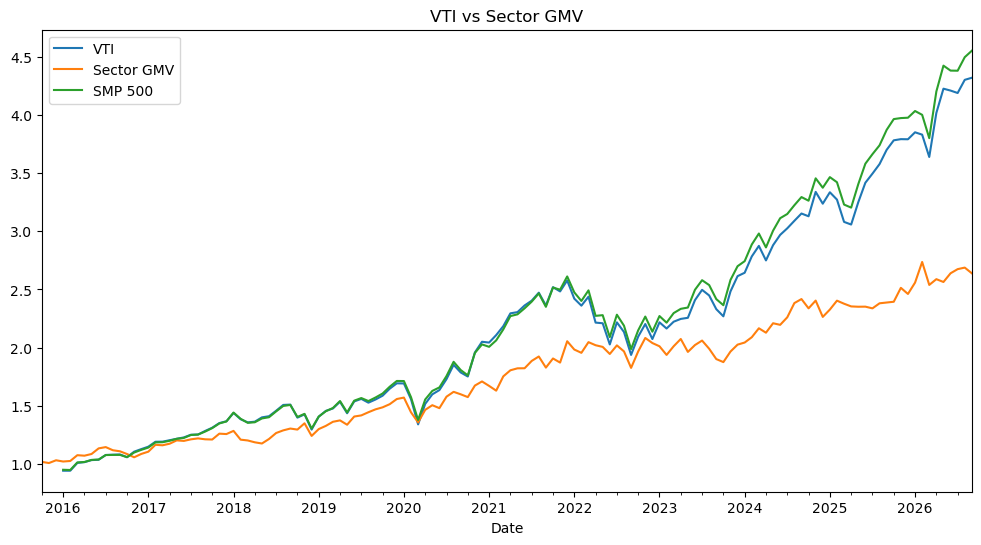

In [80]:
equity_vs_gmv = pd.DataFrame({'VTI' : vti_rets_m['2016':], 'Sector GMV' : sector_gmv_rets, 'SMP 500' : smp_500_rets_m['2016':]})
display(erk.detailed_stats(equity_vs_gmv.dropna()))
( 1 + equity_vs_gmv).cumprod().plot(figsize=(12,6), title = 'VTI vs Sector GMV')

In [81]:
# replacing the VTI returns with the GMV sleeve and checking it's worked
rets = rets.drop(columns='VTI')
rets['GMV'] = gmv_rets_d
rets

Ticker,DBC,GLD,IEF,TLT,GMV
Date,,,,,
2006-09-07,-0.003228,-0.025612,0.000732,0.001953,NaN
2006-09-08,-0.008097,-0.009959,0.000976,0.000802,NaN
2006-09-11,-0.023265,-0.035290,-0.001827,-0.000916,NaN
2006-09-12,-0.015880,-0.003077,0.002807,0.005044,NaN
2006-09-13,-0.002548,0.005144,0.000974,0.000454,NaN
...,...,...,...,...,...
2026-08-31,0.016564,-0.001149,-0.001185,-0.004344,-0.006093
2026-09-01,0.020128,-0.028574,-0.003333,-0.004075,0.004896
2026-09-02,0.000000,0.015198,0.000869,0.000977,0.004313


In [82]:
rets_2016 = rets['2016':]
shrunk_cov = erk.shrinkage_cov(rets_2016)
er_gmv_weights = erk.equal_risk_contributions(shrunk_cov)
er_gmv_weight_series = pd.Series(np.array(er_gmv_weights), index=rets_2016.columns)
er_gmv_weight_series

Ticker
DBC    0.152571
GLD    0.142426
IEF    0.353167
TLT    0.162498
GMV    0.189338
dtype: float64

/home/df73671d-916e-4a3a-9bba-0038631a0a29/edhec_risk_kit_206.py:586: FutureWarning: The provided callable <function max at 0x7991782d8c20> is currently using DataFrame.max. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "max" instead.
  best_month = r.aggregate(np.max)
/home/df73671d-916e-4a3a-9bba-0038631a0a29/edhec_risk_kit_206.py:587: FutureWarning: The provided callable <function min at 0x7991782d8d60> is currently using DataFrame.min. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "min" instead.
  worst_month = r.aggregate(np.min)


,Annualized Return,Annualized Vol,Sharpe Ratio,Sortino Ratio,Calmar Ratio,Skewness,Kurtosis,Cornish-Fisher VaR (5%),Historic CVaR (5%),Max Drawdown,Max DD Duration (mo),Hit Rate,Best Month,Worst Month
Equal weighted Portfolio,0.083043,0.078498,0.657590,1.060458,0.561979,-0.312132,3.050673,0.032142,0.043384,-0.147768,26,0.627907,0.053882,-0.064252
All Weather ER Portfolio,0.067615,0.070961,0.515843,0.801097,0.473460,-0.390506,3.252979,0.029990,0.039839,-0.142810,31,0.635659,0.048882,-0.063128
All Weather ER with GMV,0.069495,0.071652,0.536410,0.846288,0.473435,-0.361457,3.208761,0.030043,0.039828,-0.146789,30,0.643411,0.049908,-0.062432


<Axes: title={'center': 'All Weather Portfolios compared to EW Benchmark'}, xlabel='Date'>

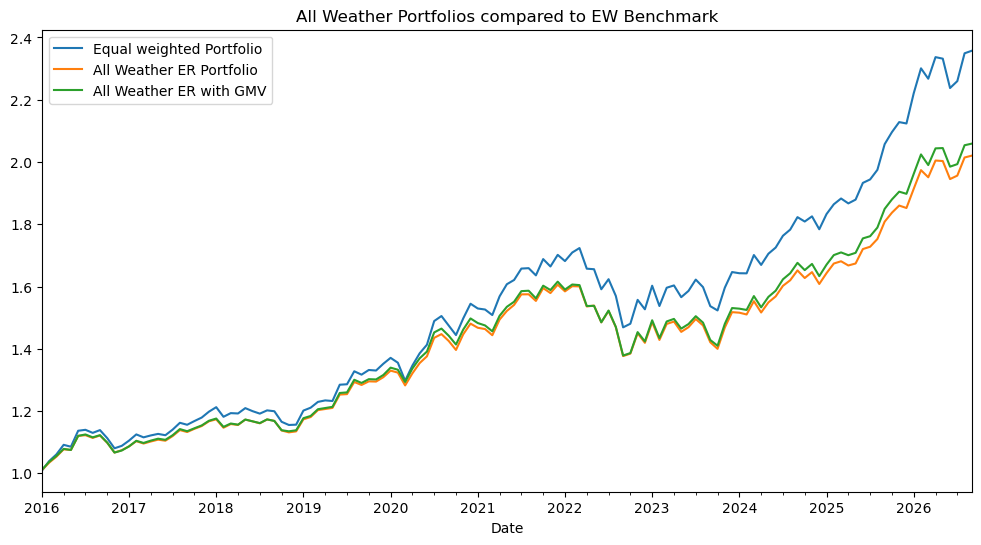

In [96]:
#'equal risk gmv backtest'
er_gmv_bt = erk.backtest_ws(monthly_rets,
                     36, 
                     weighting = lambda r: pd.Series(np.array(er_gmv_weight_series), index=r.columns))
#needs to be 2016 onwards as the gmv sleeve only has returns dating from 2016 onwards. 
bt_compared = pd.DataFrame({'Equal weighted Portfolio' : ewbt['2016':],
                            'All Weather ER Portfolio' : bt['2016':],
                            'All Weather ER with GMV' : er_gmv_bt['2016':]})
display(erk.detailed_stats(bt_compared.dropna()))
(1 + bt_compared).cumprod().plot(figsize=(12, 6), title='All Weather Portfolios compared to EW Benchmark')

##### Takeaways is that despite introducing a sleeve that is worse performing regarding returns and Sharpe Ratio, the lower volatility has allowed the portfolio with the GMV portfolio as it's equity sleeve to have a larger tilt towards equities; achieving better annualised returns whilst keeping similar volatility and even achieving a marginally smaller drawdown. Although ultimately the improvements are still marginal.

<a id='bonds'></a>
## 5. Diversifying All-Weather Portfolio: Bonds and Metals

[*********************100%***********************]  4 of 4 completed
[*********************100%***********************]  4 of 4 completed
/home/df73671d-916e-4a3a-9bba-0038631a0a29/edhec_risk_kit_206.py:586: FutureWarning: The provided callable <function max at 0x7991782d8c20> is currently using DataFrame.max. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "max" instead.
  best_month = r.aggregate(np.max)
/home/df73671d-916e-4a3a-9bba-0038631a0a29/edhec_risk_kit_206.py:587: FutureWarning: The provided callable <function min at 0x7991782d8d60> is currently using DataFrame.min. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "min" instead.
  worst_month = r.aggregate(np.min)


,Annualized Return,Annualized Vol,Sharpe Ratio,Sortino Ratio,Calmar Ratio,Skewness,Kurtosis,Cornish-Fisher VaR (5%),Historic CVaR (5%),Max Drawdown,Max DD Duration (mo),Hit Rate,Best Month,Worst Month
Bond ER Portfolio,0.018956,0.040651,-0.264464,-0.493138,0.121438,0.257043,3.198034,0.016703,0.022033,-0.156094,74,0.537313,0.032112,-0.029943
Bond GMV Portfolio,0.021744,0.060243,-0.133459,-0.252987,0.094259,0.318850,3.187566,0.024919,0.031873,-0.230681,74,0.517413,0.049559,-0.041333
Treasuries,0.024154,0.134721,-0.042396,-0.082588,0.050729,0.432164,3.414089,0.055850,0.069746,-0.476136,74,0.507463,0.132062,-0.094239
Metal ER Portfolio,0.069978,0.191634,0.202799,0.334712,0.145594,-0.229845,3.313018,0.086785,0.112240,-0.480635,106,0.567164,0.139608,-0.182179
Metal GMV Portfolio,0.067063,0.180881,0.199202,0.332743,0.140933,-0.198593,3.257351,0.081519,0.105851,-0.475852,115,0.557214,0.132250,-0.164345
Gold,0.082804,0.164788,0.311677,0.548926,0.192970,0.052070,3.023807,0.069554,0.089399,-0.429102,106,0.512438,0.122749,-0.116849


<Axes: title={'center': 'Metal and Bond Sleeve Performances'}, xlabel='Date'>

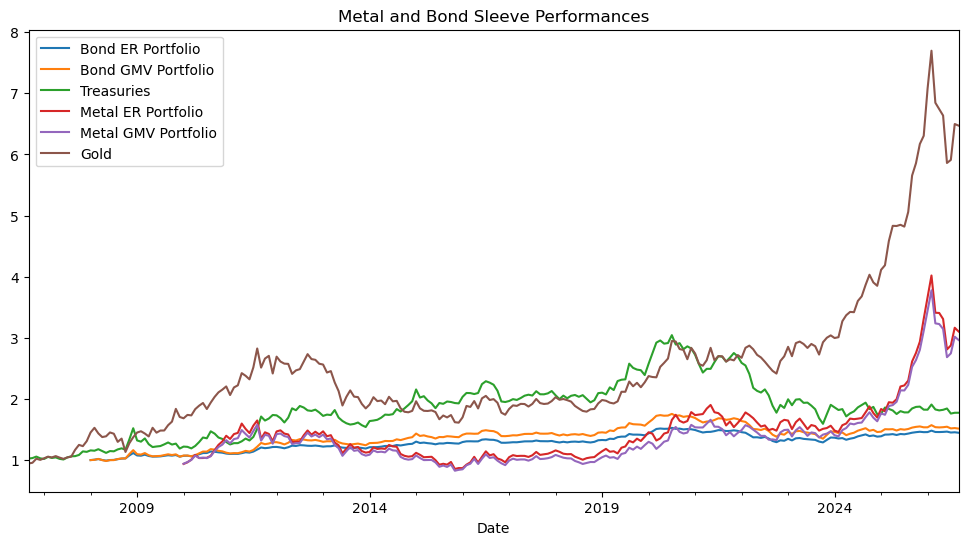

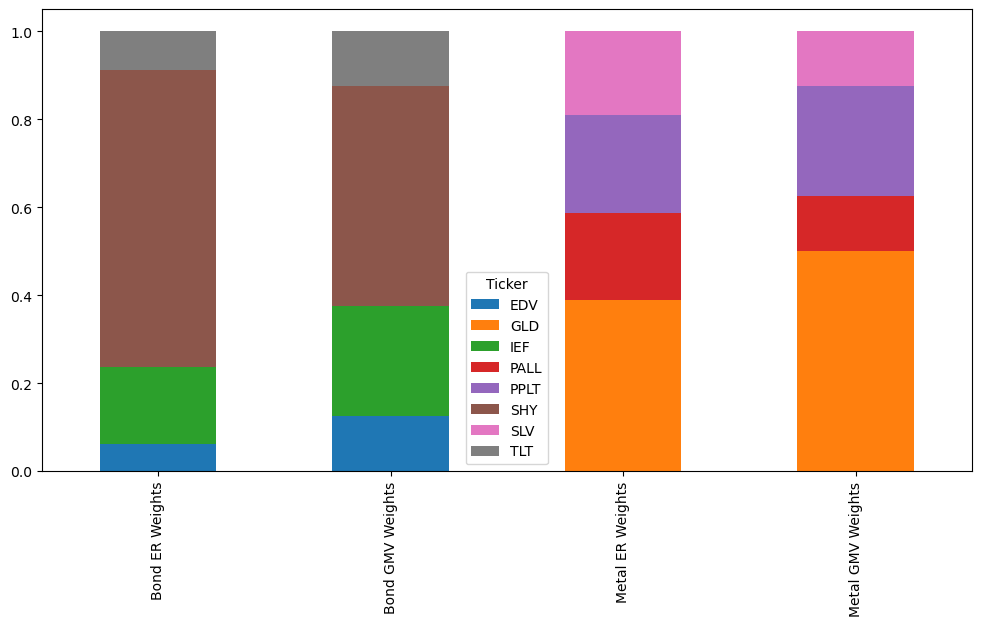

In [84]:
# Bonds and metals
bond_tickers = ['SHY', 'IEF', 'TLT', 'EDV']
metal_tickers = ['GLD', 'SLV', 'PPLT', 'PALL']

# prices
bond_prices = yf.download(bond_tickers, start='2006-09-06')['Close'].squeeze()
metal_prices = yf.download(metal_tickers, start='2006-09-06')['Close'].squeeze()

#returns and monthly returns
bond_rets = bond_prices.pct_change().dropna()
metal_rets = metal_prices.pct_change().dropna()
bond_rets_m = (1 + bond_rets).resample('ME').prod() -1
metal_rets_m = (1 + metal_rets).resample('ME').prod() -1

#asset allocation ER and GMV
bond_weights_er = pd.Series(erk.equal_risk_contributions(erk.shrinkage_cov(bond_rets['2023':])), index=bond_rets.columns)
metal_weights_er = pd.Series(erk.equal_risk_contributions(erk.shrinkage_cov(metal_rets['2023':])), index=metal_rets.columns)
bond_weights_gmv = erk.weight_gmv_bounded(erk.shrinkage_cov(bond_rets['2023':]), weight_coefficient=2)
metal_weights_gmv = erk.weight_gmv_bounded(erk.shrinkage_cov(metal_rets['2023':]), weight_coefficient=2)

#portfolio returns
bond_pfr_er = bond_rets @ bond_weights_er
bond_pfr_gmv = bond_rets @ bond_weights_gmv
metal_pfr_er = metal_rets @ metal_weights_er
metal_pfr_gmv = metal_rets @ metal_weights_gmv

#portfolio monthly returns
bond_pfr_er_m = (1 + bond_pfr_er).resample('ME').prod() -1
bond_pfr_gmv_m = (1 + bond_pfr_gmv).resample('ME').prod() -1
metal_pfr_er_m = (1 + metal_pfr_er).resample('ME').prod() -1
metal_pfr_gmv_m = (1 + metal_pfr_gmv).resample('ME').prod() -1

#stats, weightings and plots
metal_bond_sleeves = pd.DataFrame({'Bond ER Portfolio' : bond_pfr_er_m, 
                                   'Bond GMV Portfolio' : bond_pfr_gmv_m, 
                                   'Treasuries' : rets_bonds_m, 
                                   'Metal ER Portfolio' : metal_pfr_er_m, 
                                   'Metal GMV Portfolio' : metal_pfr_gmv_m, 
                                   'Gold' : rets_gold_m})
display(erk.detailed_stats(metal_bond_sleeves.dropna()))
display((1 + metal_bond_sleeves).cumprod().plot(figsize=(12, 6), title='Metal and Bond Sleeve Performances'))
metal_bond_weights = pd.DataFrame({'Bond ER Weights' : bond_weights_er, 
                                   'Bond GMV Weights' : bond_weights_gmv, 
                                   'Metal ER Weights' : metal_weights_er, 
                                   'Metal GMV Weights' : metal_weights_gmv})
metal_bond_weights.T.plot.bar(stacked=True, figsize=(12,6), legend=True);

/home/df73671d-916e-4a3a-9bba-0038631a0a29/edhec_risk_kit_206.py:586: FutureWarning: The provided callable <function max at 0x7991782d8c20> is currently using DataFrame.max. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "max" instead.
  best_month = r.aggregate(np.max)
/home/df73671d-916e-4a3a-9bba-0038631a0a29/edhec_risk_kit_206.py:587: FutureWarning: The provided callable <function min at 0x7991782d8d60> is currently using DataFrame.min. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "min" instead.
  worst_month = r.aggregate(np.min)


,Annualized Return,Annualized Vol,Sharpe Ratio,Sortino Ratio,Calmar Ratio,Skewness,Kurtosis,Cornish-Fisher VaR (5%),Historic CVaR (5%),Max Drawdown,Max DD Duration (mo),Hit Rate,Best Month,Worst Month
Bond ER Portfolio,0.025635,0.045381,-0.093672,-0.192961,0.485690,0.256362,2.638942,0.018247,0.019998,-0.052780,7,0.577778,0.032112,-0.020497
Bond GMV Portfolio,0.018299,0.064692,-0.176116,-0.346420,0.213262,0.277248,2.736189,0.027309,0.030134,-0.085804,14,0.555556,0.046065,-0.033034
Treasuries,-0.011470,0.137869,-0.292899,-0.557937,-0.056889,0.327641,2.996173,0.061183,0.069292,-0.201625,41,0.555556,0.099239,-0.079511
Metal ER Portfolio,0.181690,0.223557,0.660181,0.971100,0.604227,-0.459567,3.284722,0.096618,0.128875,-0.300697,12,0.600000,0.135897,-0.151477
Metal GMV Portfolio,0.200734,0.211106,0.786979,1.128191,0.693479,-0.536452,3.460427,0.090228,0.121260,-0.289459,12,0.622222,0.132250,-0.146584
Gold,0.262657,0.178844,1.266164,1.868162,1.101330,-0.349447,3.482057,0.067507,0.093679,-0.238491,7,0.644444,0.122732,-0.116849


<Axes: title={'center': 'Metal and Bond Sleeve Performances from 2023'}, xlabel='Date'>

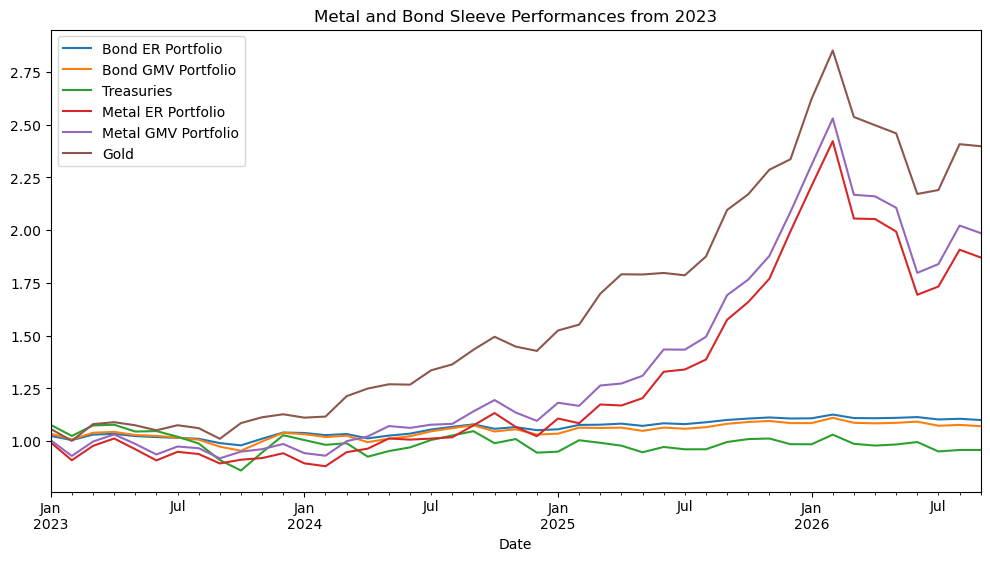

In [85]:
#stats and plots 2023 onwards
metal_bond_sleeves_23 = pd.DataFrame({'Bond ER Portfolio' : bond_pfr_er_m['2023':], 
                                      'Bond GMV Portfolio' : bond_pfr_gmv_m['2023':], 
                                      'Treasuries' : rets_bonds_m['2023':], 
                                      'Metal ER Portfolio' : metal_pfr_er_m['2023':], 
                                      'Metal GMV Portfolio' : metal_pfr_gmv_m['2023':], 
                                      'Gold' : rets_gold_m['2023':]})
display(erk.detailed_stats(metal_bond_sleeves_23.dropna()))
display((1 + metal_bond_sleeves_23).cumprod().plot(figsize=(12, 6), title='Metal and Bond Sleeve Performances from 2023'))

[*********************100%***********************]  1 of 1 completed


Gold monthly return, pre-rally baseline: 0.0032
Gold monthly return, recent (2023+): 0.0204
Annualized difference: 20.69%


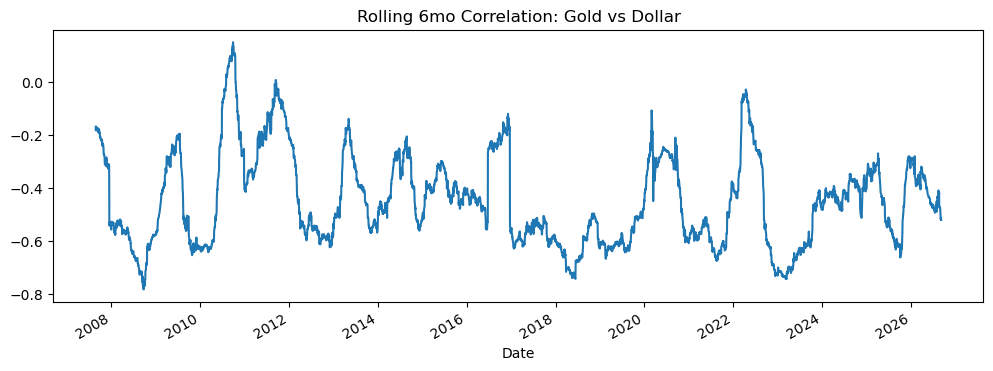

In [86]:
#dollar strenght alt prices and returns
dxy = yf.download('UUP', start='2006-09-06')['Close'].squeeze()
dxy_rets = dxy.pct_change().dropna()

# rolling correlation
aligned = pd.DataFrame({'Gold': rets_gold, 'Dollar': dxy_rets}).dropna()
rolling_corr = aligned['Gold'].rolling(126).corr(aligned['Dollar'])
rolling_corr.plot(figsize=(12,4), title='Rolling 6mo Correlation: Gold vs Dollar')

gold_hist_mean = metal_rets_m['GLD']['2006':'2019'].mean()
gold_recent_mean = metal_rets_m['GLD']['2023':].mean()

print(f"Gold monthly return, pre-rally baseline: {gold_hist_mean:.4f}")
print(f"Gold monthly return, recent (2023+): {gold_recent_mean:.4f}")
print(f"Annualized difference: {(gold_recent_mean - gold_hist_mean)*12:.2%}")

In [87]:
#explicitly splitting up the differences in performances
regimes = {'Pre-2022 (low rates and inflation)': slice('2006', '2021'), 'Post-2022 (hiking/high rate and Trump)': slice('2022', None)}

for name, period in regimes.items():
    comparison = pd.DataFrame({
        'Gold': metal_rets_m['GLD'][period],
        'TLT': bond_rets_m['TLT'][period],
        'Bond Sleeve ER': bond_pfr_er_m[period],
        'Bond Sleeve GMV': bond_pfr_gmv_m[period],
        'Metal Sleeve ER': metal_pfr_er_m[period],
        'Metal Sleeve GMV': metal_pfr_gmv_m[period]
    }).dropna()
    print(f"\n--- {name} ---")
    display(erk.summary_stats(comparison))


--- Pre-2022 (low rates and inflation) ---


,Annualized Return,Annualized Vol,Skewness,Kurtosis,Cornish-Fisher VaR (5%),Historic CVaR (5%),Sharpe Ratio,Max Drawdown
Gold,0.036360,0.161520,0.099192,2.914784,0.071133,0.086529,0.038124,-0.429102
TLT,0.070499,0.128040,0.627309,3.613869,0.046931,0.057485,0.307700,-0.200915
Bond Sleeve ER,0.028365,0.036195,0.569382,3.269389,0.012934,0.015493,-0.044015,-0.049971
Bond Sleeve GMV,0.038882,0.055424,0.566611,3.340977,0.020142,0.024076,0.155912,-0.079973
Metal Sleeve ER,0.040427,0.183607,-0.219001,3.283108,0.085105,0.106003,0.055040,-0.480635
Metal Sleeve GMV,0.031254,0.172952,-0.156129,3.114031,0.080096,0.100072,0.006839,-0.475852



--- Post-2022 (hiking/high rate and Trump) ---


,Annualized Return,Annualized Vol,Skewness,Kurtosis,Cornish-Fisher VaR (5%),Historic CVaR (5%),Sharpe Ratio,Max Drawdown
Gold,0.194269,0.172945,-0.084328,3.197161,0.066262,0.093679,0.924361,-0.238491
TLT,-0.085080,0.146696,0.297441,2.882711,0.072024,0.085367,-0.763566,-0.384394
Bond Sleeve ER,-0.004433,0.049949,0.131207,2.571981,0.023362,0.027480,-0.670959,-0.114860
Bond Sleeve GMV,-0.020305,0.070101,0.202693,2.639499,0.033474,0.038430,-0.698473,-0.175524
Metal Sleeve ER,0.148425,0.210729,-0.322571,3.300513,0.090798,0.128875,0.546738,-0.300697
Metal Sleeve GMV,0.163167,0.198756,-0.368843,3.476480,0.084514,0.121260,0.651912,-0.289459


In [88]:
equity_sleeve_rets = gmv_rets_d

corr_check = pd.DataFrame({'Equity Sleeve': equity_sleeve_rets, 
                           'Gold Alone': metal_rets_m['GLD'],
                           'Metal Sleeve': metal_pfr_er_m,
                           'TLT Alone': bond_rets_m['TLT'],
                           'Bond Sleeve': bond_pfr_er_m}).dropna()
corr_check.corr()

,Equity Sleeve,Gold Alone,Metal Sleeve,TLT Alone,Bond Sleeve
Equity Sleeve,1.000000,0.281125,0.286019,0.268949,0.287529
Gold Alone,0.281125,1.000000,0.814809,0.373870,0.421488
Metal Sleeve,0.286019,0.814809,1.000000,0.224281,0.263080
TLT Alone,0.268949,0.373870,0.224281,1.000000,0.961751
Bond Sleeve,0.287529,0.421488,0.263080,0.961751,1.000000


[*********************100%***********************]  1 of 1 completed


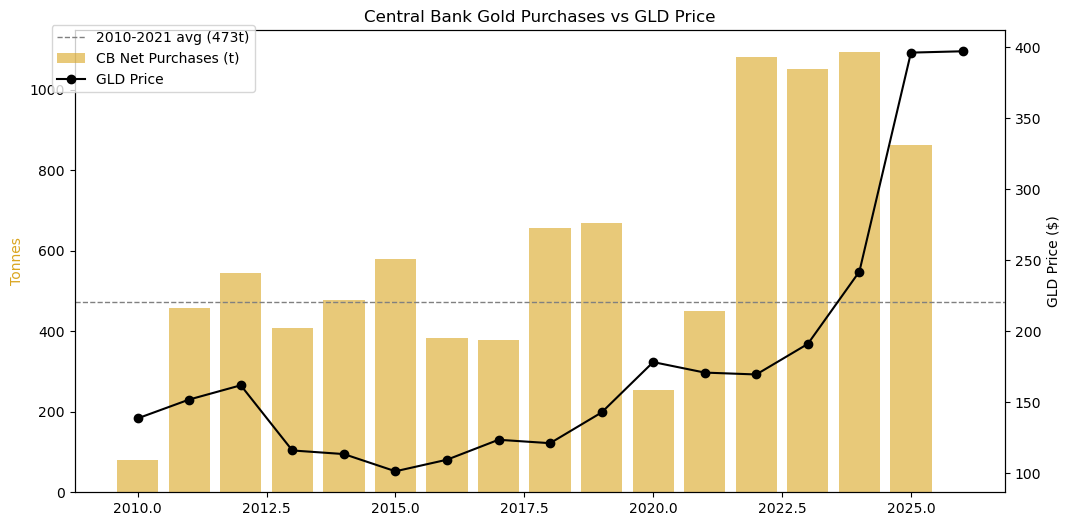

In [89]:
# Central bank annual net gold purchases (tonnes), World Gold Council
# Source: World Gold Council Gold Demand Trends reports
cb_purchases = pd.Series({
    2010: 79, 2011: 457, 2012: 544, 2013: 409, 2014: 477,
    2015: 580, 2016: 383, 2017: 379, 2018: 656, 2019: 668,
    2020: 255, 2021: 450, 2022: 1082, 2023: 1051, 2024: 1093,
    2025: 863  # full year 2025 figure
}, name='CB Net Purchases (tonnes)')

gold_price = yf.download('GLD', start='2010-01-01')['Close']
gold_annual = gold_price.resample('YE').last()
gold_annual.index = gold_annual.index.year

#plotting gold purchases from central banks against the price of gold
fig, ax1 = plt.subplots(figsize=(12,6))
ax1.bar(cb_purchases.index, cb_purchases.values, color='goldenrod', alpha=0.6, label='CB Net Purchases (t)')
ax1.set_ylabel('Tonnes', color='goldenrod')
ax1.axhline(473, color='gray', linestyle='--', linewidth=1, label='2010-2021 avg (473t)')

ax2 = ax1.twinx()
ax2.plot(gold_annual.index, gold_annual.values, color='black', marker='o', label='GLD Price')
ax2.set_ylabel('GLD Price ($)', color='black')

fig.legend(loc='upper left', bbox_to_anchor=(0.1, 0.9))
plt.title('Central Bank Gold Purchases vs GLD Price')
plt.show()

##### Despite gold rallying and perhaps with strong tailwinds for further performances, the strong trends could quickly revert to the mean if central banks slow down or reverse their gold purchases and if the dollar strengthens. Therefore despite better Sharpe Ratios and less volatility, I think the downside risks aren't being properly addressed based off of those ratios alone. That's why I am replacing an integral part of the 'All-Weather Ratio' with a precious metals sleeve that is less concentrated on gold.
##### Moreover, the recent trends for long dated treasuries and the recent long dated bond weakness in general leads me to seek the better performing ER portfolio.

##### To conclude I have chosen the ER weightings over the GMV weightings as they are still too concentrated on the assets (long-dated treasuries and gold) that I am short or want less exposure to.

<a id='sleeves'></a>
## 6. Portfolio Construction with New Sleeves

/home/df73671d-916e-4a3a-9bba-0038631a0a29/edhec_risk_kit_206.py:586: FutureWarning: The provided callable <function max at 0x7991782d8c20> is currently using DataFrame.max. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "max" instead.
  best_month = r.aggregate(np.max)
/home/df73671d-916e-4a3a-9bba-0038631a0a29/edhec_risk_kit_206.py:587: FutureWarning: The provided callable <function min at 0x7991782d8d60> is currently using DataFrame.min. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "min" instead.
  worst_month = r.aggregate(np.min)


,Annualized Return,Annualized Vol,Sharpe Ratio,Sortino Ratio,Calmar Ratio,Skewness,Kurtosis,Cornish-Fisher VaR (5%),Historic CVaR (5%),Max Drawdown,Max DD Duration (mo),Hit Rate,Best Month,Worst Month
EW Portfolio,0.096260,0.085381,0.755249,1.220420,0.651427,-0.412456,2.841674,0.035209,0.045393,-0.147768,26,0.634409,0.053882,-0.064252
AW ER Portfolio,0.077272,0.077586,0.592928,0.941183,0.541080,-0.463056,2.984446,0.033021,0.042701,-0.142810,31,0.645161,0.048882,-0.063128
AW ER w/ GMV,0.079461,0.078417,0.613813,0.995409,0.541327,-0.433843,2.933388,0.033116,0.042973,-0.146789,30,0.655914,0.049908,-0.062432
AW ER w/ Sleeves,0.060474,0.056485,0.525039,0.927899,0.728527,-0.359665,2.625131,0.023381,0.029399,-0.083009,28,0.666667,0.037886,-0.038141


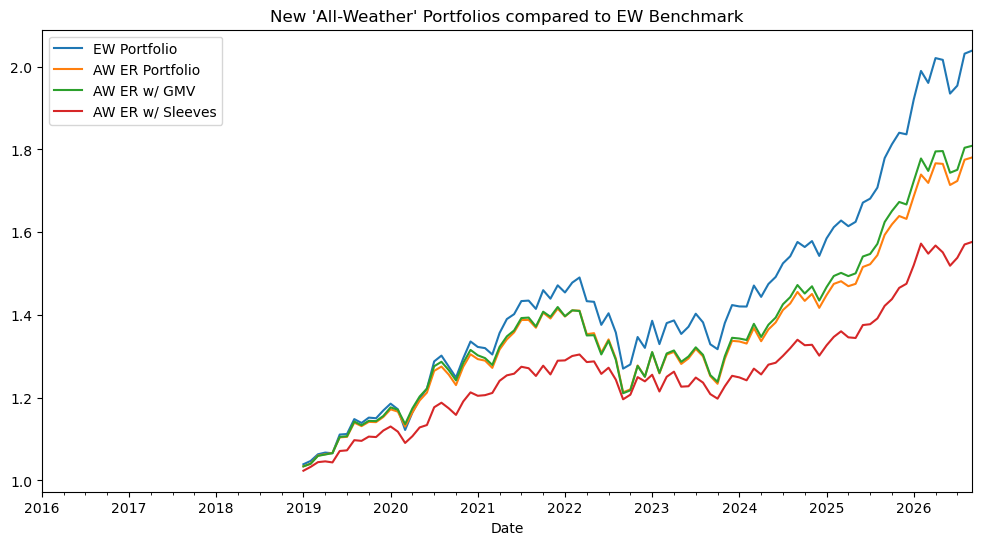

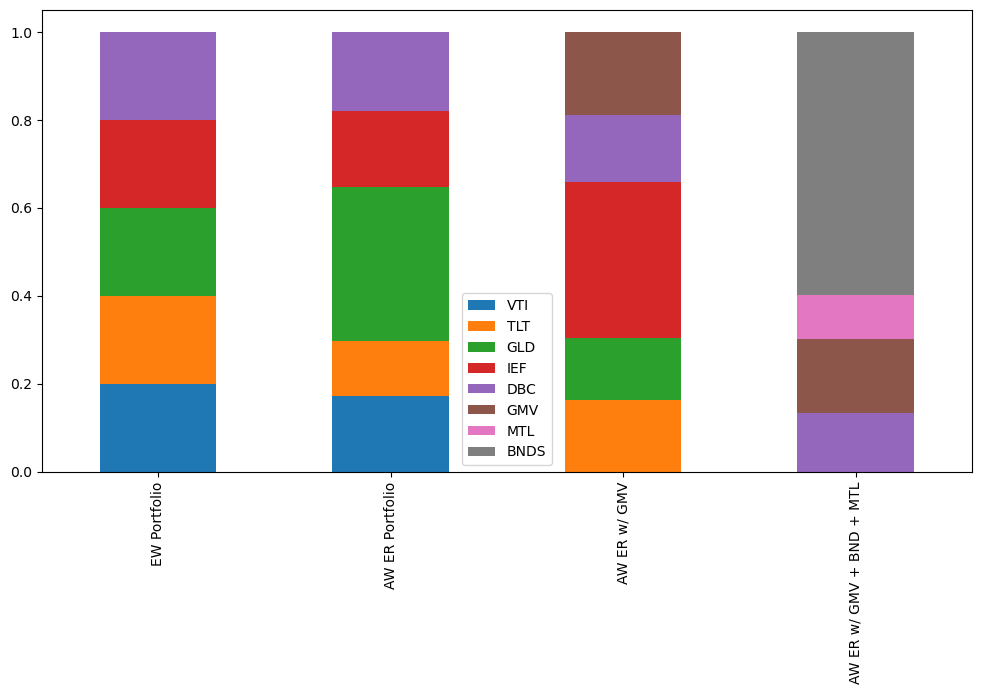

In [99]:
# Changing out old assets for new portfolios
rets_na = rets.drop(columns=['GLD', 'TLT', 'IEF'])
rets_na['MTL'] = metal_pfr_er
rets_na['BNDS'] = bond_pfr_er
rets_na['GMV'] = gmv_rets_d
rets_na_16 = rets_na['2016':]

# Monthly returns
rets_na_16_m = ( 1 + rets_na_16).resample('ME').prod() -1

# Portfolio construction
rets_na_cov = erk.shrinkage_cov(rets_na_16)
er_sleeves_weights = erk.equal_risk_contributions(rets_na_cov)
er_sleeves_weights_series = pd.Series(np.array(er_sleeves_weights), index=rets_na_16.columns)
er_sleeves_bt = erk.backtest_ws(rets_na_16_m,
                                36, 
                                weighting = lambda r: pd.Series(np.array(er_sleeves_weights_series), index=r.columns))

# Stats and Plot 
bt_compared_with_sleeve_p = pd.DataFrame({'EW Portfolio' : ewbt['2019':],
                                          'AW ER Portfolio' : bt['2019':],
                                          'AW ER w/ GMV' : er_gmv_bt['2019':],
                                          'AW ER w/ Sleeves' : er_sleeves_bt})
display(erk.detailed_stats(bt_compared_with_sleeve_p.dropna()))
(1 + bt_compared_with_sleeve_p).cumprod().plot(figsize=(12, 6), title="New 'All-Weather' Portfolios compared to EW Benchmark")

# Bar of weights
ew_weights_bar = pd.Series(np.repeat(0.2, 5), index=tickers)
er_weights_bar = pd.Series(er_weights, index=tickers)
er_gmv_weights_bar = pd.Series(er_gmv_weights, index=rets_2016.columns)
er_sleeves_weights_bar = pd.Series(er_sleeves_weights, index=rets_na_16.columns)
aw_weights = pd.concat({'EW Portfolio' : ew_weights_bar,
                           'AW ER Portfolio' : er_weights_bar,
                           'AW ER w/ GMV' : er_gmv_weights_bar,
                           'AW ER w/ GMV + BND + MTL' : er_sleeves_weights_bar
                          }, axis=1)
aw_weights.T.plot.bar(stacked=True, figsize=(12,6), legend=True);

##### By reducing the volatility of the metals and bonds sections of the portfolio it's now allocated a large portion of the portfolio to bonds which in comparison have perfomred poorly compared to the other assets.

In [ ]:
<a id='constraint'></a>
## 7. Constraints to Equal Risk Portfolio

/home/df73671d-916e-4a3a-9bba-0038631a0a29/edhec_risk_kit_206.py:586: FutureWarning: The provided callable <function max at 0x7991782d8c20> is currently using DataFrame.max. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "max" instead.
  best_month = r.aggregate(np.max)
/home/df73671d-916e-4a3a-9bba-0038631a0a29/edhec_risk_kit_206.py:587: FutureWarning: The provided callable <function min at 0x7991782d8d60> is currently using DataFrame.min. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "min" instead.
  worst_month = r.aggregate(np.min)


,Annualized Return,Annualized Vol,Sharpe Ratio,Sortino Ratio,Calmar Ratio,Skewness,Kurtosis,Cornish-Fisher VaR (5%),Historic CVaR (5%),Max Drawdown,Max DD Duration (mo),Hit Rate,Best Month,Worst Month
NO Constraints,0.060474,0.056485,0.525039,0.927899,0.728527,-0.359665,2.625131,0.023381,0.029399,-0.083009,28,0.666667,0.037886,-0.038141
55%,0.066209,0.060538,0.582077,1.021919,0.781859,-0.366545,2.615155,0.024985,0.031912,-0.084681,28,0.666667,0.041341,-0.039073
54%,0.067396,0.061414,0.592588,1.038266,0.792662,-0.368233,2.616660,0.025336,0.032435,-0.085025,28,0.666667,0.042053,-0.039268
53%,0.068586,0.062305,0.602695,1.054142,0.803393,-0.369863,2.619002,0.025694,0.032958,-0.085370,28,0.666667,0.042771,-0.039456
52%,0.069776,0.063210,0.612387,1.068821,0.814019,-0.371463,2.622166,0.026059,0.033479,-0.085717,27,0.666667,0.043490,-0.039643
51%,0.070967,0.064122,0.621762,1.082220,0.824648,-0.373504,2.627029,0.026429,0.034007,-0.086057,27,0.666667,0.044202,-0.039835
50%,0.072160,0.065055,0.630681,1.094852,0.835078,-0.374898,2.631379,0.026806,0.034525,-0.086411,27,0.666667,0.044933,-0.040010
49%,0.073351,0.065994,0.639278,1.126267,0.845465,-0.376659,2.637154,0.027188,0.035047,-0.086758,27,0.677419,0.045655,-0.040193
48%,0.074543,0.066940,0.647574,1.137091,0.855828,-0.378747,2.644266,0.027575,0.035574,-0.087101,27,0.677419,0.046371,-0.040381
47%,0.075738,0.067901,0.655546,1.147058,0.866116,-0.380750,2.651834,0.027969,0.036100,-0.087446,27,0.677419,0.047094,-0.040561


<Axes: title={'center': 'ER Compared with Constraints'}, xlabel='Date'>

<Axes: >

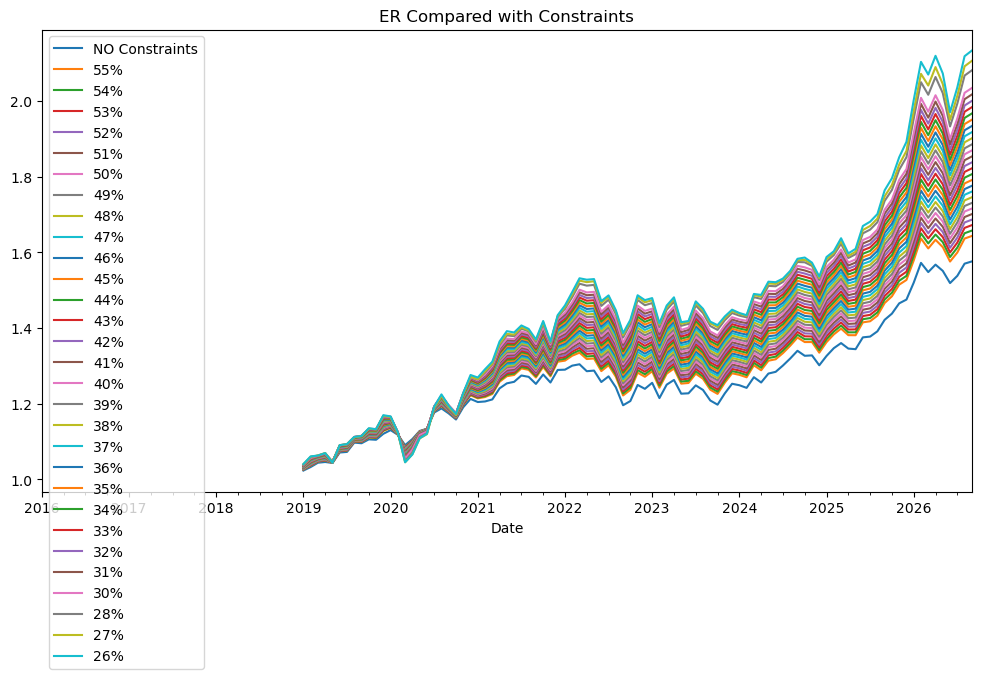

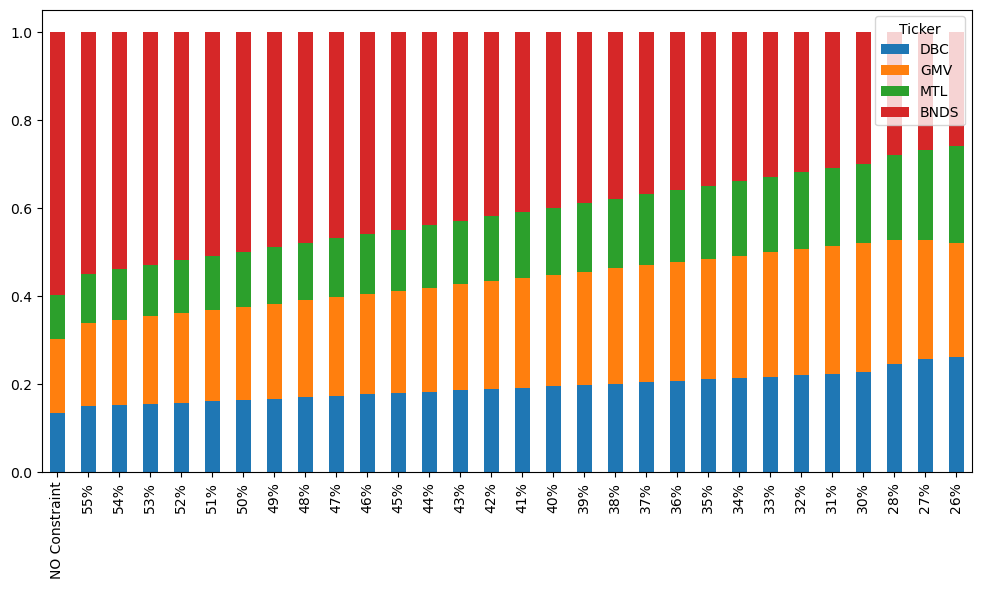

In [92]:
# Adding weight constraints to small asset based portfolio. Define the function, use the function to recreate portfolio then compare and contrast with each other at different constraints

results_constraints = {'NO Constraints' : er_sleeves_bt}
bar_constraints = {'NO Constraint' : er_sleeves_weights_bar}

for max_w_pct in np.arange(55, 25, -1):
    max_w = max_w_pct / 100
    title = f"{int(max_w * 100)}%"
    w = erk.equal_risk_contributions_bounds(rets_na_cov, 0, max_weight=max_w)
    w_series = pd.Series(np.array(w), index=rets_na_16.columns)
    # loops the backtest for each constraint
    constraint_bt_loop = erk.backtest_ws(rets_na_16_m,
                                36, 
                                weighting = lambda r: pd.Series(np.array(w_series), index=r.columns))
    results_constraints[title] = constraint_bt_loop
    # loops the weights of each asset for bar graph
    weights_4_bar = pd.Series(w, index=rets_na_16.columns)
    bar_constraints[title] = weights_4_bar

results_df = pd.DataFrame(results_constraints)
bt_stats = erk.detailed_stats(results_df.dropna())

higher_is_better = ['Sortino Ratio', 'Sharpe Ratio', 'Calmar Ratio', 'Annualized Return', 'Hit Rate', 'Best Month', 'Worst Month', 'Max Drawdown']
lower_is_better = ['Annualized Vol', 'Historic CVaR (5%)', 'Cornish-Fisher VaR (5%)', 'Max DD Duration (mo)']
from matplotlib.colors import LinearSegmentedColormap
red_green = LinearSegmentedColormap.from_list('red_green', ['lightcoral', 'lightgreen'])

styled_stats = bt_stats.style \
    .background_gradient(subset=higher_is_better, cmap=red_green) \
    .background_gradient(subset=lower_is_better, cmap=red_green.reversed())
display(styled_stats)
plot_constraints = (1 + results_df).cumprod().plot(figsize=(12, 6), title='ER Compared with Constraints')
display(plot_constraints)
bar_constraints_df = pd.DataFrame(bar_constraints)
display(bar_constraints_df.T.plot.bar(stacked=True, figsize=(12,6), legend=True))

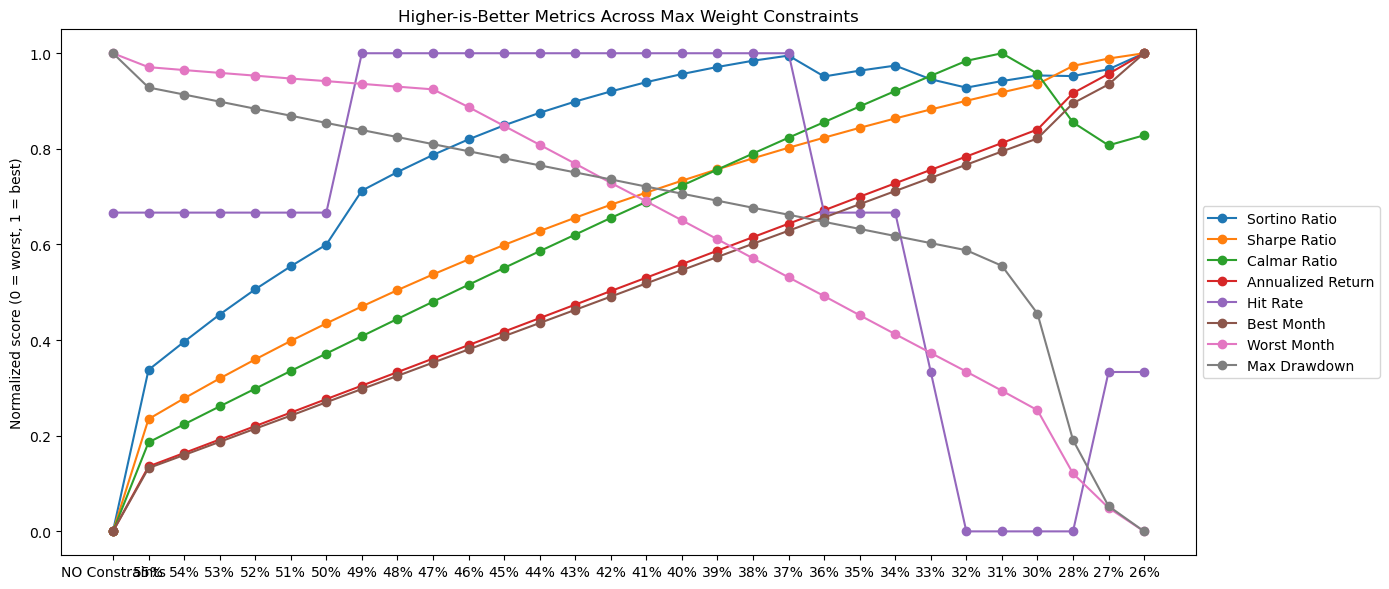

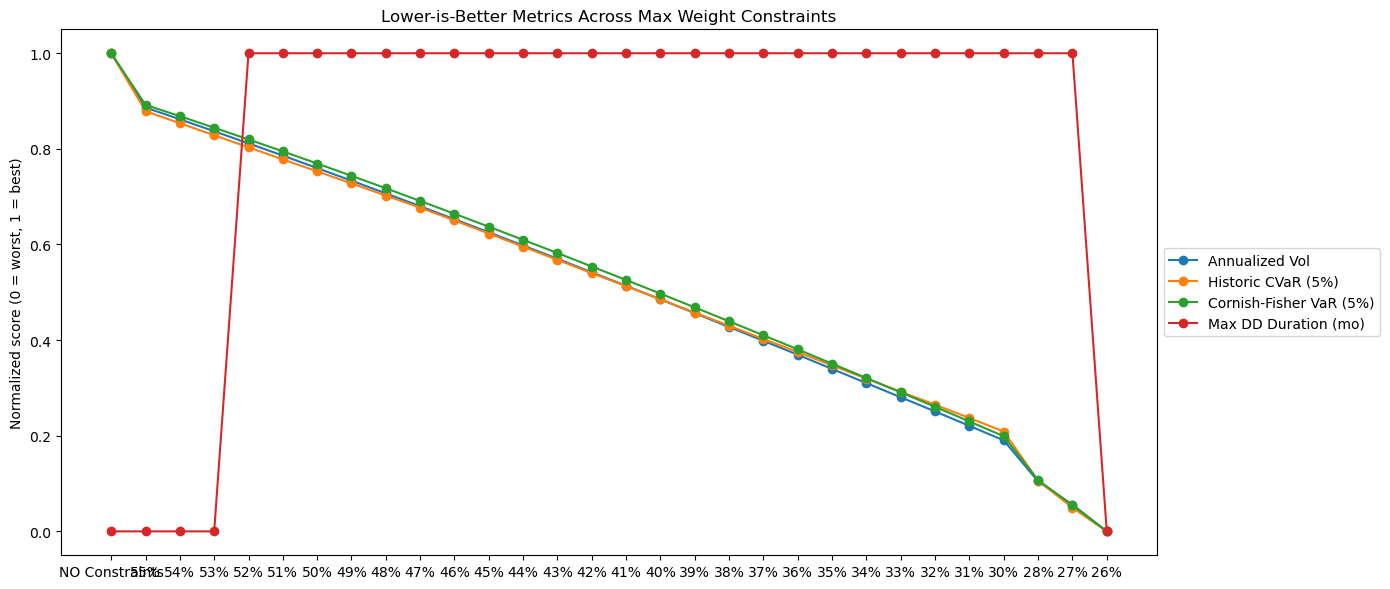

In [93]:
normalized_hib = bt_stats[higher_is_better].copy()
for col in higher_is_better:
    normalized_hib[col] = (bt_stats[col] - bt_stats[col].min()) / (bt_stats[col].max() - bt_stats[col].min())

normalized_lib = bt_stats[lower_is_better].copy()
for col in lower_is_better:
    normalized_lib[col] = (bt_stats[col].max() - bt_stats[col]) / (bt_stats[col].max() - bt_stats[col].min())

# Plot 1: higher-is-better metrics
ax1 = normalized_hib.plot(figsize=(14, 6), marker='o', title='Higher-is-Better Metrics Across Max Weight Constraints')
ax1.set_xticks(range(len(normalized_hib.index)))
ax1.set_xticklabels(normalized_hib.index, rotation=0)
ax1.set_ylabel('Normalized score (0 = worst, 1 = best)')
ax1.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))
plt.tight_layout()
plt.show()

# Plot 2: lower-is-better metrics
ax2 = normalized_lib.plot(figsize=(14, 6), marker='o', title='Lower-is-Better Metrics Across Max Weight Constraints')
ax2.set_xticks(range(len(normalized_lib.index)))
ax2.set_xticklabels(normalized_lib.index, rotation=0)
ax2.set_ylabel('Normalized score (0 = worst, 1 = best)')
ax2.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))
plt.tight_layout()
plt.show()

/home/df73671d-916e-4a3a-9bba-0038631a0a29/edhec_risk_kit_206.py:586: FutureWarning: The provided callable <function max at 0x7991782d8c20> is currently using DataFrame.max. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "max" instead.
  best_month = r.aggregate(np.max)
/home/df73671d-916e-4a3a-9bba-0038631a0a29/edhec_risk_kit_206.py:587: FutureWarning: The provided callable <function min at 0x7991782d8d60> is currently using DataFrame.min. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "min" instead.
  worst_month = r.aggregate(np.min)


,Annualized Return,Annualized Vol,Sharpe Ratio,Sortino Ratio,Calmar Ratio,Skewness,Kurtosis,Cornish-Fisher VaR (5%),Historic CVaR (5%),Max Drawdown,Max DD Duration (mo),Hit Rate,Best Month,Worst Month
EW Portfolio,0.096260,0.085381,0.755249,1.220420,0.651427,-0.412456,2.841674,0.035209,0.045393,-0.147768,26,0.634409,0.053882,-0.064252
AW ER Portfolio,0.077272,0.077586,0.592928,0.941183,0.541080,-0.463056,2.984446,0.033021,0.042701,-0.142810,31,0.645161,0.048882,-0.063128
AW ER w/ GMV,0.079461,0.078417,0.613813,0.995409,0.541327,-0.433843,2.933388,0.033116,0.042973,-0.146789,30,0.655914,0.049908,-0.062432
AW ER w/ Sleeves,0.060474,0.056485,0.525039,0.927899,0.728527,-0.359665,2.625131,0.023381,0.029399,-0.083009,28,0.666667,0.037886,-0.038141
Bounded ER Sleeve Portfolio,0.084084,0.074854,0.703149,1.194142,0.935675,-0.396087,2.720303,0.030848,0.040076,-0.089864,27,0.677419,0.052141,-0.049339


<Axes: title={'center': 'Portfolios Compared'}, xlabel='Date'>

<Axes: >

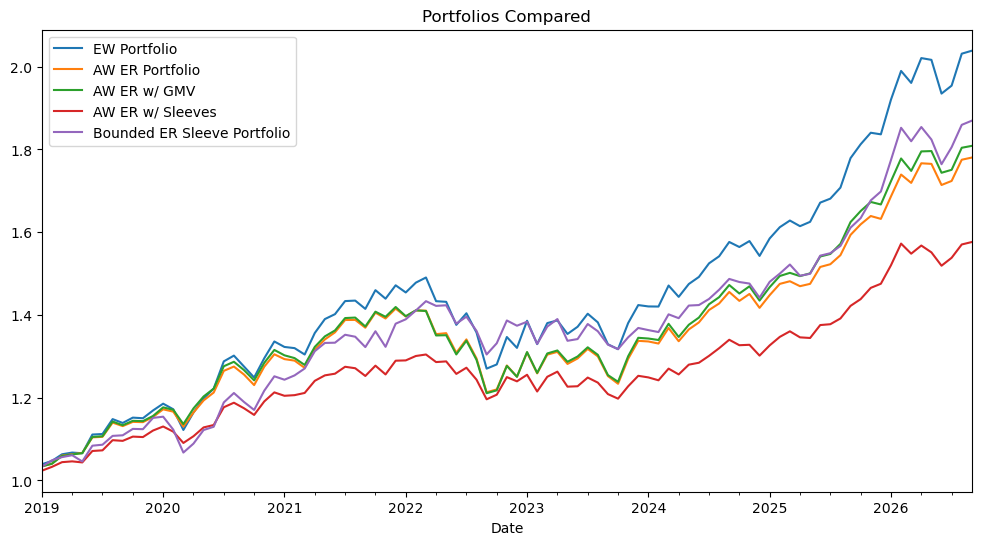

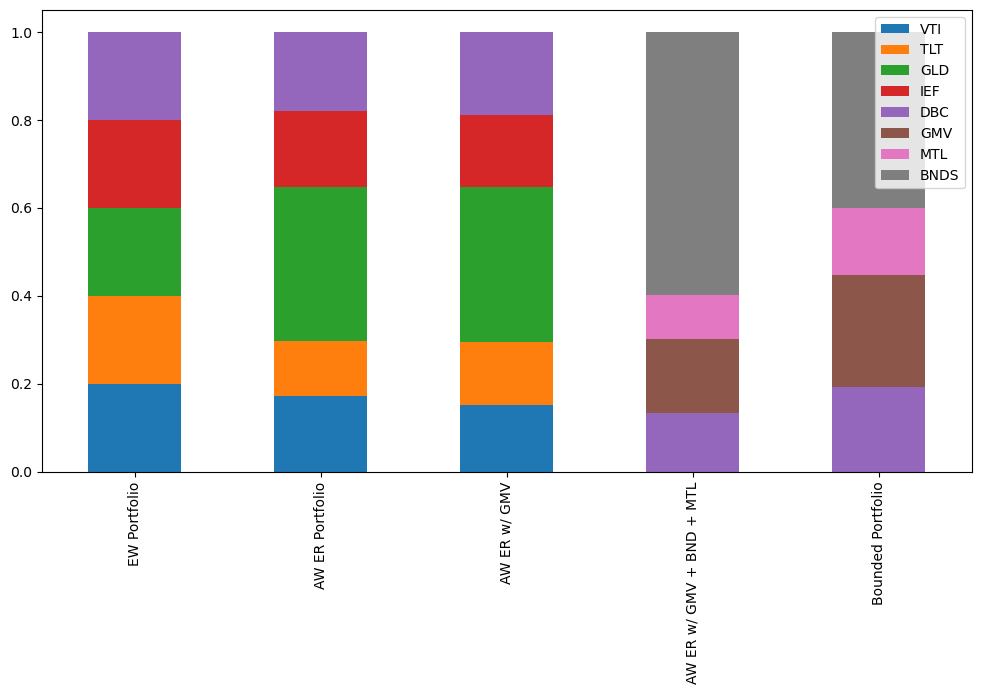

In [94]:
# 40% is where the marginal benefits for the Sortino and Sharpe Ratio either decline or the marginal improvement is slowing down.
# Hit rate peaked around 40-47%
# drawdown duration was almost constant

# the drops off with worse risk performance metrics were noticable past 30%
# lets now compare the max 40% portfolio with the others. I chose 40% because the data pointed to this general area and I felt 40-45% of my portfolio being bonds was good and getting the precise amount would be overfitting to get the best from this particular data.

# Adding weight constraints to small asset based portfolio. Define the function, use the function to recreate portfolio then compare and contrast with each other at different constraints


bounded_pf_40 = erk.equal_risk_contributions_bounds(rets_na_cov, 0, max_weight= 0.4)
bounded_series = pd.Series(np.array(bounded_pf_40), index=rets_na_16.columns)
bounded_bt_40 = erk.backtest_ws(rets_na_16_m,
                                36, 
                                weighting = lambda r: pd.Series(np.array(bounded_series), index=r.columns))
# weights for bar graph
bounded_40_bar = pd.Series(bounded_pf_40, index=rets_na_16.columns)

bt_final = bt_compared_with_sleeve_p.copy().dropna()
bt_final['Bounded ER Sleeve Portfolio'] = bounded_bt_40
bt_final_stats = erk.detailed_stats(bt_final)

bt_final_stats_styled = bt_final_stats.style \
    .background_gradient(subset=higher_is_better, cmap=red_green) \
    .background_gradient(subset=lower_is_better, cmap=red_green.reversed())
display(bt_final_stats_styled)
plot_bt_final = (1 + bt_final).cumprod().plot(figsize=(12, 6), title='Portfolios Compared')
display(plot_bt_final)

bar_final = aw_weights.copy()
bar_final['Bounded Portfolio'] = bounded_40_bar
display(bar_final.T.plot.bar(stacked=True, figsize=(12,6), legend=True))

<a id='conclusion'></a>
## 8. Conclusion

##### The traditionally weighted portfolio has performed worse in volatility and draw downs, that's because it's meant to include leverage. Let's see how leverage affects the risk parity portfolio's weights.

#### In the face of a difficult and complex market that we find ourselves with inflationary pressures from the middle east, asset bubbles from AI, retail and central banks elevating gold prices and the sovereign bond selloff; the original all weather portfolio begins to appear brittle. As it stands there is a lot of headwinds for three of the five assets that: equities, all the indexes have concentration risk into AI; sticky inflation and low growth amongst the G7 undermines long dated treasuries and gold has had an unprecedented bull run that could unwind in the face of a dollar rebound or a pause in central bank purchases. Therefore, this portfolio structually reduces the sensitivity of these headwinds by diversifying, adding new securities into each asset class and I have increased the weighting of equities which was a key driver in improving risk adjusted returns whilst making the bond portfolio less volatile and improving drawdown performance against the initial all weather portfolio. 

#### What worked best was introducing the GMV sleeve as it elevated the total risk adjusted performance of the total portfolio by becoming a larger component due to it's low volatility. This was impoved further when metals and bonds were further diversified and then placed into a maximum weight equal risk portfolio that showed significant improvement in the Sortino Ratio and Hit rate of the portfolio in the backtest compared to my benchmark portfolios.

#### The decision to pursue a 40% max weight portfolio was because the initial portfolio including the new metal, bond and GMV sleeves overweighted the bond portfolio too heavily at 59%. Leaving it vulnerable to inflation and US policy shocks whilst reducing the risk adjust return. The 40% maximum weight was chosen because key data points such as the Sortino and Sharpe Ratios improvement declined as this weight decreased and key risk metrics such as volatility and drawdown rose faster past a 30% max weight. Although for this data a maximum weight of 38% had the best Sortino Ratio and Hit Rate, choosing a precise maximum weight such as 38% would be overfitting the portfolio weights to the data at hand, likely hamstringing out of sample performance.

#### A major weakness is that the weights of the portfolio are't rebalanced using previous data, which does defeat the purpose of placing a limit on the initial weighting as it lets high returning assets like gold and equities grow unrestricted. Without rebalancing, the longer the backtest goes, the less relevant the weighting scheme becomes. Moreover, due to the limited nature of the new instruments I introduced, their price history only goes as far back for 2016 and 2019. Although the initial portfolio created does cover key crisises such as the financial crash which showcases the portfolio does still perform in a bear market, I'd have liked to test my new portfolio in those scenarios. Furthermore, it's high returns could be affected by recent trends such as the global equity and gold rally. The drawdown duration was also only marginally affected when inputting a cap from 27 months to 28, making it a poor metric to measure these portfolios, making drawdown a more explicit measure to evaluate performance.

#### Going forward I would like to create a backtest that goes further back and uses the past three years of data to create ERC and GMV portfolios that are then rebalanced using the max weight logic possibly allowing for some positions to grow before profit taking. Also take into account rebalancing costs and possibly adapting the portfolio for different regimes such as falling rates and rising rates.